# Hackathlon 2026 - Bayesian Bandits

"A közbeszerzések mekkora része tekinthető kockázatosnak egyszerű, adatból levezethető szempontok alapján, és ezek közül mennyi köthető magántőkealapokhoz?"

Állítás 1: A vizsgált közbeszerzések egy része kockázati jegyeket mutat.

Állítás 2: A kockázatos közbeszerzések között jelentős arányban jelennek meg magántőkealapokhoz köthető cégek.

### Fájl beolvasása, pandasba illesztés, oszlopok listázása, azok átnevezése

In [2]:
import os
# import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.decomposition import PCA
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.model_selection import GridSearchCV

In [ ]:
FILE="hackathon_magántőkealapok.xlsx"
xlsx=pd.ExcelFile(FILE)
print("Munkalapok:", xlsx.sheet_names)

Munkalapok: ['1_Magántőkealapok', '2_Alapkezelők', '3_Céltársaságok', '4_Közbeszerzések']


In [ ]:
funds_raw=pd.read_excel(FILE, sheet_name="1_Magántőkealapok")
managers_raw=pd.read_excel(FILE, sheet_name="2_Alapkezelők")
targets_raw=pd.read_excel(FILE, sheet_name="3_Céltársaságok")
proc_raw=pd.read_excel(FILE, sheet_name="4_Közbeszerzések")


In [ ]:
print("funds_raw:", funds_raw.shape)
print("managers_raw:", managers_raw.shape)
print("targets_raw:", targets_raw.shape)
print("proc_raw:", proc_raw.shape)

funds_raw: (194, 14)
managers_raw: (60, 13)
targets_raw: (1896, 20)
proc_raw: (2262, 13)


In [ ]:
print(funds_raw.columns.tolist())
print(managers_raw.columns.tolist())
print(targets_raw.columns.tolist())
print(proc_raw.columns.tolist())

['Magántőkealap bejegyzett neve', 'Adószám', 'DUNS', 'D&B ID', 'Törzsszám vagy technikai törzsszám', 'MNB határozat szám', 'Alapkezelő neve', 'Alapkezelő cégbírósági nyilvántartási száma', 'Magántőkealap nettó eszközértéke, 2023 (millió Ft)', 'Magántőkealap eszközértéke, 2024 (millió Ft)', 'Állami befektető szervezet elnevezése', 'Állami szervezetek által befektetett pénzügyi eszközök, 2024 (millió Ft)', 'Állami szervezetek részesedése, 2024 (%)', 'A magántőkealap által 2024.12.31-ig kibocsátott aktív befektetési jegyek összértéke (millió Ft)']
['Alapkezelő neve', 'Alapkezelő székhelye', 'Alapkezelő cégbírósági nyilvántartási száma', 'Adószám', 'DUNS', 'Rövid név', 'Előző bejegyzett nevek', 'Cím (Bejegyzett) Irsz', 'Város', 'Utca', 'Vármegye (Bejegyzett)', 'Végső tulajdonosok', 'Végső magánszemély tulajdonosok']
['Cég neve', 'A cég székhelye, ország', 'Cég adószáma', 'DUNS', 'Tulajdonos magántőkealap neve', 'Tulajdonos magántőkealap D&B ID-ja', 'Szint azonosító', 'Mélység a tulajdonosi

In [7]:
#Csak ak utatáshoz szükséges változókat tartjuk meg

funds = funds_raw[[
    "Magántőkealap bejegyzett neve",
    "DUNS",
    "D&B ID",
    "Alapkezelő neve",
    "Magántőkealap eszközértéke, 2024 (millió Ft)",
    "Állami befektető szervezet elnevezése",
    "Állami szervezetek által befektetett pénzügyi eszközök, 2024 (millió Ft)",
    "Állami szervezetek részesedése, 2024 (%)"
]].copy()

funds.columns = [
    "fund_name",
    "fund_duns",
    "fund_dbid",
    "manager_name",
    "fund_value_2024_m_huf",
    "state_investor_name",
    "state_investment_2024_m_huf",
    "state_share_2024_pct"
]

managers = managers_raw[[
    "Alapkezelő neve",
    "Végső tulajdonosok",
    "Végső magánszemély tulajdonosok"
]].copy()

managers.columns = [
    "manager_name",
    "ultimate_owners",
    "ultimate_natural_persons"
]

targets = targets_raw[[
    "Cég neve",
    "DUNS",
    "Tulajdonos magántőkealap neve",
    "Tulajdonos magántőkealap D&B ID-ja",
    "Mélység a tulajdonosi fában",
    "Van-e állami befektetés (1=igen, 0= nem)",
    "Értékesítés nettó árbevétele (2024, HUF)",
    "Negatív esemény"
]].copy()

targets.columns = [
    "company_name",
    "company_duns",
    "fund_name",
    "fund_dbid",
    "ownership_depth",
    "has_state_investment",
    "revenue_2024_huf",
    "negative_event"
]

proc = proc_raw[[
    "A nyertes cég neve",
    "DUNS",
    "A hirdetmény közzétételének dátuma",
    "Közbeszerzés elnevezése",
    "A beszerzés értéke (Ft) ",
    "Egyedül / konzorciumban",
    "Nyertes cégek száma konzorcium esetén",
    "Fő CPV kód (a beszerzés tárgyának besorolása)",
    "Ajánlatkérő szervezet"
]].copy()

proc.columns = [
    "company_name",
    "company_duns",
    "notice_date",
    "proc_title",
    "proc_value_huf",
    "solo_or_consortium",
    "consortium_winner_count",
    "cpv_code",
    "buyer_name"
]

print("Shapes:")
print("funds:", funds.shape)
print("managers:", managers.shape)
print("targets:", targets.shape)
print("proc:", proc.shape)

Shapes:
funds: (194, 8)
managers: (60, 3)
targets: (1896, 8)
proc: (2262, 9)


### Adattisztítás

In [8]:
proc["notice_date"] = pd.to_datetime(proc["notice_date"], errors="coerce")

proc["proc_value_huf"] = (
    proc["proc_value_huf"]
    .astype("string")
    .str.replace("\xa0", "", regex=False)
    .str.replace(" ", "", regex=False)
    .str.replace(",", ".", regex=False)
    .str.replace(r"[^0-9\.\-]", "", regex=True)
    .pipe(pd.to_numeric, errors="coerce")
)

proc["consortium_winner_count"] = (
    proc["consortium_winner_count"]
    .astype("string")
    .str.replace(r"[^0-9\.\-]", "", regex=True)
    .pipe(pd.to_numeric, errors="coerce")
)

targets["ownership_depth"] = (
    targets["ownership_depth"]
    .astype("string")
    .str.replace(r"[^0-9\.\-]", "", regex=True)
    .pipe(pd.to_numeric, errors="coerce")
)

targets["has_state_investment"] = (
    targets["has_state_investment"]
    .astype("string")
    .str.replace(r"[^0-9\.\-]", "", regex=True)
    .pipe(pd.to_numeric, errors="coerce")
)

targets["revenue_2024_huf"] = (
    targets["revenue_2024_huf"]
    .astype("string")
    .str.replace("\xa0", "", regex=False)
    .str.replace(" ", "", regex=False)
    .str.replace(",", ".", regex=False)
    .str.replace(r"[^0-9\.\-]", "", regex=True)
    .pipe(pd.to_numeric, errors="coerce")
)

funds["fund_value_2024_m_huf"] = (
    funds["fund_value_2024_m_huf"]
    .astype("string")
    .str.replace("\xa0", "", regex=False)
    .str.replace(" ", "", regex=False)
    .str.replace(",", ".", regex=False)
    .str.replace(r"[^0-9\.\-]", "", regex=True)
    .pipe(pd.to_numeric, errors="coerce")
)

funds["state_investment_2024_m_huf"] = (
    funds["state_investment_2024_m_huf"]
    .astype("string")
    .str.replace("\xa0", "", regex=False)
    .str.replace(" ", "", regex=False)
    .str.replace(",", ".", regex=False)
    .str.replace(r"[^0-9\.\-]", "", regex=True)
    .pipe(pd.to_numeric, errors="coerce")
)

funds["state_share_2024_pct"] = (
    funds["state_share_2024_pct"]
    .astype("string")
    .str.replace("%", "", regex=False)
    .str.replace(",", ".", regex=False)
    .str.replace(r"[^0-9\.\-]", "", regex=True)
    .pipe(pd.to_numeric, errors="coerce")
)

print("Minimal preprocessing done.")
print("\nproc dtypes:\n", proc.dtypes)
print("\ntargets dtypes:\n", targets.dtypes)
print("\nfunds dtypes:\n", funds.dtypes)

Minimal preprocessing done.

proc dtypes:
 company_name                       object
company_duns                        int64
notice_date                datetime64[ns]
proc_title                         object
proc_value_huf                    Float64
solo_or_consortium                 object
consortium_winner_count           Float64
cpv_code                           object
buyer_name                         object
dtype: object

targets dtypes:
 company_name             object
company_duns              int64
fund_name                object
fund_dbid                 int64
ownership_depth           Int64
has_state_investment      Int64
revenue_2024_huf        Float64
negative_event           object
dtype: object

funds dtypes:
 fund_name                       object
fund_duns                      float64
fund_dbid                      float64
manager_name                    object
fund_value_2024_m_huf          Float64
state_investor_name             object
state_investment_2024_m_huf

In [9]:
display(funds.head(3))
display(managers.head(3))
display(targets.head(3))
display(proc.head(3))

print("Missing values in targets:")
print(targets.isna().sum())

print("\nMissing values in proc:")
print(proc.isna().sum())

,fund_name,fund_duns,fund_dbid,manager_name,fund_value_2024_m_huf,state_investor_name,state_investment_2024_m_huf,state_share_2024_pct
0,Konzum Pe Magántőkealap,401457706.0,10024437.0,OPUS GLOBAL Befektetési Alapkezelő Zrt.,340973.0,NaN,<NA>,<NA>
1,Global Alfa Magántőkealap,851795569.0,11690367.0,OPUS GLOBAL Befektetési Alapkezelő Zrt.,199570.0,NaN,<NA>,<NA>
2,Indotek-Ventures Alpha Magántőkealap,851792784.0,11685160.0,Indotek-Investments Alapkezelő Zrt.,183888.593,Magyar Fejlesztési Bank,50000.0,70.0


,manager_name,ultimate_owners,ultimate_natural_persons
0,Accessio Equity Partners Kockázati Tőkealap-ke...,Közép-Európai Vállalkozók Együttműködéséért Al...,"Dr. Bartha János Péter (cím: 1125 Budapest, Tü..."
1,Arx Prime Kockázati Tőkealap-kezelő Zrt.,"Dr. Baráti Ákos Pál (cím: 1124 Budapest, Ormód...","Dr. Baráti Ákos Pál (cím: 1124 Budapest, Ormód..."
2,Atlas Europe Assets Kockázati és Magán Tőkeala...,"Szécsényi Bálint (cím: 1125 Budapest, Zalai út...","Szécsényi Bálint (cím: 1125 Budapest, Zalai út..."


,company_name,company_duns,fund_name,fund_dbid,ownership_depth,has_state_investment,revenue_2024_huf,negative_event
0,FUNDUS Tüköry Ingatlanforgalmazó Korlátolt Fel...,401425197,Ane Magántőkealap,11822534,1,0,<NA>,NaN
1,Balancing Power Europe Zártkörűen Működő Részv...,851838028,Arezzo Magántőkealap,11173227,2,0,<NA>,NaN
2,Zsiros Kakuch Solar Korlátolt Felelősségű Társ...,987915310,Arezzo Magántőkealap,11173227,2,0,<NA>,NaN


,company_name,company_duns,notice_date,proc_title,proc_value_huf,solo_or_consortium,consortium_winner_count,cpv_code,buyer_name
0,MBH Bank Nyilvánosan Működő Részvénytársaság,364734442,2024-01-08,Számlavezetés és folyószámlahitel nyújtása,3000000000.0,egyedül,<NA>,66110000-4,Dunántúli Regionális Vízmű Zártkörűen Működő R...
1,MBH Bank Nyilvánosan Működő Részvénytársaság,364734442,2023-11-24,MFB Pont Plusz vállalati hálózat kialakítása,12821571498.5,konzorciumban,2.0,66150000-6,MFB Magyar Fejlesztési Bank Zártkörűen Működő ...
2,Publimont Hirdetésszervező Korlátolt Felelőssé...,401496062,2023-06-13,Közterületi reklámfelületek vásárlása,12822000.0,egyedül,<NA>,79341000-6,Margitszigeti Színház Nonprofit Korlátolt Fele...


Missing values in targets:
company_name               0
company_duns               0
fund_name                  0
fund_dbid                  0
ownership_depth            0
has_state_investment       0
revenue_2024_huf        1191
negative_event          1122
dtype: int64

Missing values in proc:
company_name                  0
company_duns                  0
notice_date                   0
proc_title                    0
proc_value_huf                7
solo_or_consortium            0
consortium_winner_count    1129
cpv_code                      0
buyer_name                    0
dtype: int64


### közbeszerzések összekötése a céltársaságokkal DUNS alapján

In [ ]:
# Most építjük meg az első elemző alaptáblát: közbeszerzés + céltársaság + alap
# A cél hogy minden tender sornál lássuk: 
# melyik cég nyert,
# PE-kapcsolatban van-e,
# melyik fundhoz tartozik,
# van-e állami érintettsége,
# ki az alapkezelő,
# mennyi a tender értéke,
# mi a buyer/cpv/dátum.

proc_targets = proc.merge(
    targets,
    on="company_duns",
    how="left",
    suffixes=("_proc", "_target")
)

print("proc_targets shape:", proc_targets.shape)

display(
    proc_targets[[
        "company_name_proc",
        "company_duns",
        "proc_value_huf",
        "fund_name",
        "has_state_investment",
        "ownership_depth"
    ]].head(10)
)

print("\nHiányzók a join után:")
print(proc_targets[[
    "fund_name",
    "has_state_investment",
    "ownership_depth"
]].isna().sum())

# ha a nyertes cég benne van a céltársaságok között, akkor megkapja a fund-kapcsolatot és az állami érintettséget. Ez lesz a PE-link alapja.

proc_targets shape: (3095, 16)


,company_name_proc,company_duns,proc_value_huf,fund_name,has_state_investment,ownership_depth
0,MBH Bank Nyilvánosan Működő Részvénytársaság,364734442,3000000000.0,Aurum Magántőkealap,0,2
1,MBH Bank Nyilvánosan Működő Részvénytársaság,364734442,3000000000.0,Global Alfa Magántőkealap,0,2
2,MBH Bank Nyilvánosan Működő Részvénytársaság,364734442,3000000000.0,Metis Magántőkealap,0,2
3,MBH Bank Nyilvánosan Működő Részvénytársaság,364734442,3000000000.0,Shihon Magántőkealap,0,2
4,MBH Bank Nyilvánosan Működő Részvénytársaság,364734442,12821571498.5,Aurum Magántőkealap,0,2
5,MBH Bank Nyilvánosan Működő Részvénytársaság,364734442,12821571498.5,Global Alfa Magántőkealap,0,2
6,MBH Bank Nyilvánosan Működő Részvénytársaság,364734442,12821571498.5,Metis Magántőkealap,0,2
7,MBH Bank Nyilvánosan Működő Részvénytársaság,364734442,12821571498.5,Shihon Magántőkealap,0,2
8,Publimont Hirdetésszervező Korlátolt Felelőssé...,401496062,12822000.0,Prime Blanc Magántőkealap,0,1
9,Publimont Hirdetésszervező Korlátolt Felelőssé...,401496062,12822000.0,Prime Target Magántőkealap,0,1



Hiányzók a join után:
fund_name               148
has_state_investment    148
ownership_depth         148
dtype: int64


### Alapok hozzácsatolása fund alapján

In [11]:
#Itt nem DUNS alapján joinolunk, hanem a fund_dbid a legjobb kulcs. 
#Ha valahol ez hiányos lenne, később nézhetjük fund_name alapján is, de elsőre ez a tisztább.

proc_targets_funds = proc_targets.merge(
    funds,
    on="fund_dbid",
    how="left",
    suffixes=("", "_fund")
)

print("proc_targets_funds shape:", proc_targets_funds.shape)

display(
    proc_targets_funds[[
        "company_name_proc",
        "company_duns",
        "fund_name",
        "manager_name",
        "has_state_investment",
        "state_investment_2024_m_huf",
        "state_share_2024_pct",
        "proc_value_huf"
    ]].head(10)
)

print("\nFund-level hiányzók:")
print(proc_targets_funds[[
    "manager_name",
    "state_investment_2024_m_huf",
    "state_share_2024_pct"
]].isna().sum())

proc_targets_funds shape: (3095, 23)


,company_name_proc,company_duns,fund_name,manager_name,has_state_investment,state_investment_2024_m_huf,state_share_2024_pct,proc_value_huf
0,MBH Bank Nyilvánosan Működő Részvénytársaság,364734442,Aurum Magántőkealap,QUARTZ Befektetési Alapkezelő Zrt.,0,<NA>,<NA>,3000000000.0
1,MBH Bank Nyilvánosan Működő Részvénytársaság,364734442,Global Alfa Magántőkealap,OPUS GLOBAL Befektetési Alapkezelő Zrt.,0,<NA>,<NA>,3000000000.0
2,MBH Bank Nyilvánosan Működő Részvénytársaság,364734442,Metis Magántőkealap,OPUS GLOBAL Befektetési Alapkezelő Zrt.,0,<NA>,<NA>,3000000000.0
3,MBH Bank Nyilvánosan Működő Részvénytársaság,364734442,Shihon Magántőkealap,Citadel Alapkezelő Zrt.,0,<NA>,<NA>,3000000000.0
4,MBH Bank Nyilvánosan Működő Részvénytársaság,364734442,Aurum Magántőkealap,QUARTZ Befektetési Alapkezelő Zrt.,0,<NA>,<NA>,12821571498.5
5,MBH Bank Nyilvánosan Működő Részvénytársaság,364734442,Global Alfa Magántőkealap,OPUS GLOBAL Befektetési Alapkezelő Zrt.,0,<NA>,<NA>,12821571498.5
6,MBH Bank Nyilvánosan Működő Részvénytársaság,364734442,Metis Magántőkealap,OPUS GLOBAL Befektetési Alapkezelő Zrt.,0,<NA>,<NA>,12821571498.5
7,MBH Bank Nyilvánosan Működő Részvénytársaság,364734442,Shihon Magántőkealap,Citadel Alapkezelő Zrt.,0,<NA>,<NA>,12821571498.5
8,Publimont Hirdetésszervező Korlátolt Felelőssé...,401496062,Prime Blanc Magántőkealap,INITIA CAPITAL Befektetési Alapkezelő Zrt.,0,<NA>,<NA>,12822000.0
9,Publimont Hirdetésszervező Korlátolt Felelőssé...,401496062,Prime Target Magántőkealap,INITIA CAPITAL Befektetési Alapkezelő Zrt.,0,<NA>,<NA>,12822000.0



Fund-level hiányzók:
manager_name                      0
state_investment_2024_m_huf    1953
state_share_2024_pct           2665
dtype: int64


### PE-kapcsolat és állami érintettség flag-ek

In [ ]:
analysis_df = proc_targets_funds.copy()

# PE-kapcsolat: ha van fund_name vagy fund_dbid, akkor van kapcsolat
analysis_df["pe_link_flag"] = (
    analysis_df["fund_name"].notna() | analysis_df["fund_dbid"].notna()
).astype("Int64")

# Állami érintettség a céltársaság oldali változó alapján
analysis_df["state_pe_flag"] = analysis_df["has_state_investment"].map({
    1: 1,
    0: 0
}).astype("Int64")

# Fund oldali állami pénz jelenlét
analysis_df["state_fund_money_flag"] = pd.Series(pd.NA, index=analysis_df.index, dtype="Int64")
analysis_df.loc[
    analysis_df["state_investment_2024_m_huf"].notna() & (analysis_df["state_investment_2024_m_huf"] > 0),
    "state_fund_money_flag"
] = 1
analysis_df.loc[
    analysis_df["state_investment_2024_m_huf"].notna() & (analysis_df["state_investment_2024_m_huf"] <= 0),
    "state_fund_money_flag"
] = 0

display(
    analysis_df[[
        "company_name_proc",
        "company_duns",
        "fund_name",
        "pe_link_flag",
        "has_state_investment",
        "state_pe_flag",
        "state_investment_2024_m_huf",
        "state_fund_money_flag",
        "proc_value_huf"
    ]].head(10)
)

print(analysis_df[["pe_link_flag", "state_pe_flag", "state_fund_money_flag"]].dtypes)


# state_pe_flag: a céltársaságok táblájából jövő közvetlen jelölés
# state_fund_money_flag: a fund oldali állami befektetési mezőből jövő információ

,company_name_proc,company_duns,fund_name,pe_link_flag,has_state_investment,state_pe_flag,state_investment_2024_m_huf,state_fund_money_flag,proc_value_huf
0,MBH Bank Nyilvánosan Működő Részvénytársaság,364734442,Aurum Magántőkealap,1,0,0,<NA>,<NA>,3000000000.0
1,MBH Bank Nyilvánosan Működő Részvénytársaság,364734442,Global Alfa Magántőkealap,1,0,0,<NA>,<NA>,3000000000.0
2,MBH Bank Nyilvánosan Működő Részvénytársaság,364734442,Metis Magántőkealap,1,0,0,<NA>,<NA>,3000000000.0
3,MBH Bank Nyilvánosan Működő Részvénytársaság,364734442,Shihon Magántőkealap,1,0,0,<NA>,<NA>,3000000000.0
4,MBH Bank Nyilvánosan Működő Részvénytársaság,364734442,Aurum Magántőkealap,1,0,0,<NA>,<NA>,12821571498.5
5,MBH Bank Nyilvánosan Működő Részvénytársaság,364734442,Global Alfa Magántőkealap,1,0,0,<NA>,<NA>,12821571498.5
6,MBH Bank Nyilvánosan Működő Részvénytársaság,364734442,Metis Magántőkealap,1,0,0,<NA>,<NA>,12821571498.5
7,MBH Bank Nyilvánosan Működő Részvénytársaság,364734442,Shihon Magántőkealap,1,0,0,<NA>,<NA>,12821571498.5
8,Publimont Hirdetésszervező Korlátolt Felelőssé...,401496062,Prime Blanc Magántőkealap,1,0,0,<NA>,<NA>,12822000.0
9,Publimont Hirdetésszervező Korlátolt Felelőssé...,401496062,Prime Target Magántőkealap,1,0,0,<NA>,<NA>,12822000.0


pe_link_flag             Int64
state_pe_flag            Int64
state_fund_money_flag    Int64
dtype: object


### Ellenőrzés

In [13]:
summary_check = pd.DataFrame({
    "metric": [
        "all_proc_rows",
        "pe_linked_rows",
        "non_pe_rows",
        "state_pe_rows",
        "total_proc_value",
        "pe_proc_value",
        "state_pe_proc_value"
    ],
    "value": [
        len(analysis_df),
        int((analysis_df["pe_link_flag"] == 1).sum()),
        int((analysis_df["pe_link_flag"] == 0).sum()),
        int((analysis_df["state_pe_flag"] == 1).sum()),
        analysis_df["proc_value_huf"].sum(),
        analysis_df.loc[analysis_df["pe_link_flag"] == 1, "proc_value_huf"].sum(),
        analysis_df.loc[analysis_df["state_pe_flag"] == 1, "proc_value_huf"].sum()
    ]
})

display(summary_check)

#Ebből készítünk risk_score és risk_categoryt

,metric,value
0,all_proc_rows,3.095000e+03
1,pe_linked_rows,2.947000e+03
2,non_pe_rows,1.480000e+02
3,state_pe_rows,1.249000e+03
4,total_proc_value,3.368980e+12
5,pe_proc_value,2.377331e+12
6,state_pe_proc_value,1.288861e+12


In [14]:
#arányok számítása
total_rows = len(analysis_df)
pe_rows = (analysis_df["pe_link_flag"] == 1).sum()
non_pe_rows = (analysis_df["pe_link_flag"] == 0).sum()
state_pe_rows = (analysis_df["state_pe_flag"] == 1).sum()

total_value = analysis_df["proc_value_huf"].sum()
pe_value = analysis_df.loc[analysis_df["pe_link_flag"] == 1, "proc_value_huf"].sum()
state_pe_value = analysis_df.loc[analysis_df["state_pe_flag"] == 1, "proc_value_huf"].sum()

summary_pct = pd.DataFrame({
    "mutató": [
        "PE-kapcsolatú közbeszerzési sorok aránya (%)",
        "Nem PE-kapcsolatú közbeszerzési sorok aránya (%)",
        "Állami érintettségű PE-kapcsolatú sorok aránya (%)",
        "PE-kapcsolatú közbeszerzési érték aránya (%)",
        "Állami érintettségű PE-kapcsolatú közbeszerzési érték aránya (%)"
    ],
    "érték": [
        pe_rows / total_rows * 100,
        non_pe_rows / total_rows * 100,
        state_pe_rows / total_rows * 100,
        pe_value / total_value * 100,
        state_pe_value / total_value * 100
    ]
})

summary_pct["érték"] = summary_pct["érték"].round(2)

display(summary_pct)

,mutató,érték
0,PE-kapcsolatú közbeszerzési sorok aránya (%),95.22
1,Nem PE-kapcsolatú közbeszerzési sorok aránya (%),4.78
2,Állami érintettségű PE-kapcsolatú sorok aránya...,40.36
3,PE-kapcsolatú közbeszerzési érték aránya (%),70.57
4,Állami érintettségű PE-kapcsolatú közbeszerzés...,38.26


A vizsgált közbeszerzési adatbázisban a magántőkealapokhoz kapcsolódó cégek domináns jelenléte rajzolódik ki. Nemcsak a közbeszerzési sorok döntő többsége kapcsolódik ilyen cégekhez, hanem az összes közbeszerzési érték több mint 70%-a is. Az állami érintettségű magántőkealapokhoz kötődő cégek önmagukban is a teljes közbeszerzési érték közel 40%-át adják.

### Kockázati indikátorok létrehozása, utána risk_score

In [15]:
#cégszintű aggregáció
#Előbb csináljunk egy company summary-t, mert néhány flag cégszintű lesz.

company_summary = (
    analysis_df
    .groupby("company_duns", dropna=False)
    .agg(
        company_name=("company_name_proc", "first"),
        proc_count=("company_duns", "size"),
        total_proc_value=("proc_value_huf", "sum"),
        avg_proc_value=("proc_value_huf", "mean"),
        unique_buyers=("buyer_name", "nunique"),
        top_buyer_proc_count=("buyer_name", lambda x: x.value_counts(dropna=False).max()),
        pe_link_flag=("pe_link_flag", "max"),
        state_pe_flag=("state_pe_flag", "max"),
        ownership_depth=("ownership_depth", "max"),
        revenue_2024_huf=("revenue_2024_huf", "max"),
        fund_name=("fund_name", "first"),
        manager_name=("manager_name", "first")
    )
    .reset_index()
)

display(company_summary.head())
print(company_summary.shape)

,company_duns,company_name,proc_count,total_proc_value,avg_proc_value,unique_buyers,top_buyer_proc_count,pe_link_flag,state_pe_flag,ownership_depth,revenue_2024_huf,fund_name,manager_name
0,364734442,MBH Bank Nyilvánosan Működő Részvénytársaság,8,63286285994.0,7910785749.25,2,4,1,0,2,<NA>,Aurum Magántőkealap,QUARTZ Befektetési Alapkezelő Zrt.
1,366609343,MBH Forrás Pénzügyi Tanácsadó és Vállalkozásfe...,12,3041800000.0,253483333.333333,3,4,1,0,3,161652000.0,Aurum Magántőkealap,QUARTZ Befektetési Alapkezelő Zrt.
2,366613462,ACE Network Zártkörűen Működő Részvénytársaság,74,28859684003.030235,389995729.770679,5,62,1,1,3,10430969000.0,Ig Com Magántőkealap,iKON Befektetési Alapkezelő Zrt.
3,366622540,Waterscope Zártkörűen Működő Részvénytársaság,1,8220300.0,8220300.0,1,1,1,1,1,228879000.0,Kék Bolygó Víz Alap,KBKB Kék Bolygó Klímavédelmi Befektetési Alapk...
4,366626314,Mészáros M1 Autókereskedő Korlátolt Felelősség...,27,13248961246.0,490702268.37037,15,5,1,1,1,18458791000.0,Mbh Magántőkealap,Solus Capital Kockázati Tőkealap-kezelő Zrt.


(91, 13)


In [ ]:
#buyer dependency kiszámítása

company_summary["top_buyer_share"] = (
    company_summary["top_buyer_proc_count"] / company_summary["proc_count"]
)

display(
    company_summary[[
        "company_name",
        "proc_count",
        "unique_buyers",
        "top_buyer_proc_count",
        "top_buyer_share"
    ]].head(10)
)

,company_name,proc_count,unique_buyers,top_buyer_proc_count,top_buyer_share
0,MBH Bank Nyilvánosan Működő Részvénytársaság,8,2,4,0.500000
1,MBH Forrás Pénzügyi Tanácsadó és Vállalkozásfe...,12,3,4,0.333333
2,ACE Network Zártkörűen Működő Részvénytársaság,74,5,62,0.837838
3,Waterscope Zártkörűen Működő Részvénytársaság,1,1,1,1.000000
4,Mészáros M1 Autókereskedő Korlátolt Felelősség...,27,15,5,0.185185
5,FABETKER Kereskedelmi és Szolgáltató Korlátolt...,1,1,1,1.000000
6,Adept Enviro Korlátolt Felelősségű Társaság,3,3,1,0.333333
7,"Chem-System Ipari, Kereskedelmi és Szolgáltató...",2,1,2,1.000000
8,Invitech ICT Services Korlátolt Felelősségű Tá...,448,34,290,0.647321
9,MOL Fleet Solution Flottakezelő Korlátolt Fele...,1,1,1,1.000000


In [17]:
# küszöbök meghatározása

high_value_threshold = analysis_df["proc_value_huf"].quantile(0.90)
repeat_winner_threshold = company_summary["proc_count"].quantile(0.90)

print(f"High value threshold (90. percentilis): {high_value_threshold:,.0f} Ft")
print(f"Repeat winner threshold (90. percentilis): {repeat_winner_threshold:.0f} nyerés")

High value threshold (90. percentilis): 1,157,248,566 Ft
Repeat winner threshold (90. percentilis): 74 nyerés


In [ ]:
#Cégszintű mutatók visszacsatolása tenderszintre

analysis_df = analysis_df.merge(
    company_summary[[
        "company_duns",
        "proc_count",
        "top_buyer_share"
    ]],
    on="company_duns",
    how="left"
)

display(
    analysis_df[[
        "company_name_proc",
        "company_duns",
        "proc_value_huf",
        "proc_count",
        "top_buyer_share"
    ]].head(10)
)

,company_name_proc,company_duns,proc_value_huf,proc_count,top_buyer_share
0,MBH Bank Nyilvánosan Működő Részvénytársaság,364734442,3000000000.0,8,0.500000
1,MBH Bank Nyilvánosan Működő Részvénytársaság,364734442,3000000000.0,8,0.500000
2,MBH Bank Nyilvánosan Működő Részvénytársaság,364734442,3000000000.0,8,0.500000
3,MBH Bank Nyilvánosan Működő Részvénytársaság,364734442,3000000000.0,8,0.500000
4,MBH Bank Nyilvánosan Működő Részvénytársaság,364734442,12821571498.5,8,0.500000
5,MBH Bank Nyilvánosan Működő Részvénytársaság,364734442,12821571498.5,8,0.500000
6,MBH Bank Nyilvánosan Működő Részvénytársaság,364734442,12821571498.5,8,0.500000
7,MBH Bank Nyilvánosan Működő Részvénytársaság,364734442,12821571498.5,8,0.500000
8,Publimont Hirdetésszervező Korlátolt Felelőssé...,401496062,12822000.0,6,0.666667
9,Publimont Hirdetésszervező Korlátolt Felelőssé...,401496062,12822000.0,6,0.666667


In [19]:
# Kockázati flag-ek létrehozása

analysis_df["high_value_flag"] = (
    analysis_df["proc_value_huf"] >= high_value_threshold
).astype("Int64")

analysis_df["repeat_winner_flag"] = (
    analysis_df["proc_count"] >= repeat_winner_threshold
).astype("Int64")

analysis_df["buyer_dependency_flag"] = (
    analysis_df["top_buyer_share"] > 0.5
).astype("Int64")

analysis_df["single_bid_like_flag"] = (
    analysis_df["solo_or_consortium"].astype("string").str.lower() == "egyedül"
).astype("Int64")

display(
    analysis_df[[
        "company_name_proc",
        "proc_value_huf",
        "proc_count",
        "top_buyer_share",
        "solo_or_consortium",
        "high_value_flag",
        "repeat_winner_flag",
        "buyer_dependency_flag",
        "single_bid_like_flag"
    ]].head(10)
)

,company_name_proc,proc_value_huf,proc_count,top_buyer_share,solo_or_consortium,high_value_flag,repeat_winner_flag,buyer_dependency_flag,single_bid_like_flag
0,MBH Bank Nyilvánosan Működő Részvénytársaság,3000000000.0,8,0.500000,egyedül,1,0,0,1
1,MBH Bank Nyilvánosan Működő Részvénytársaság,3000000000.0,8,0.500000,egyedül,1,0,0,1
2,MBH Bank Nyilvánosan Működő Részvénytársaság,3000000000.0,8,0.500000,egyedül,1,0,0,1
3,MBH Bank Nyilvánosan Működő Részvénytársaság,3000000000.0,8,0.500000,egyedül,1,0,0,1
4,MBH Bank Nyilvánosan Működő Részvénytársaság,12821571498.5,8,0.500000,konzorciumban,1,0,0,0
5,MBH Bank Nyilvánosan Működő Részvénytársaság,12821571498.5,8,0.500000,konzorciumban,1,0,0,0
6,MBH Bank Nyilvánosan Működő Részvénytársaság,12821571498.5,8,0.500000,konzorciumban,1,0,0,0
7,MBH Bank Nyilvánosan Működő Részvénytársaság,12821571498.5,8,0.500000,konzorciumban,1,0,0,0
8,Publimont Hirdetésszervező Korlátolt Felelőssé...,12822000.0,6,0.666667,egyedül,0,0,1,1
9,Publimont Hirdetésszervező Korlátolt Felelőssé...,12822000.0,6,0.666667,egyedül,0,0,1,1


In [20]:
#Risk score és category

risk_flag_cols = [
    "high_value_flag",
    "repeat_winner_flag",
    "buyer_dependency_flag",
    "single_bid_like_flag"
]

analysis_df["risk_score"] = analysis_df[risk_flag_cols].sum(axis=1)

analysis_df["risk_category"] = pd.cut(
    analysis_df["risk_score"],
    bins=[-1, 1, 2, 4],
    labels=["alacsony", "közepes", "magas"]
)

display(
    analysis_df[[
        "company_name_proc",
        "proc_value_huf",
        "risk_score",
        "risk_category"
    ]].head(10)
)

print(analysis_df["risk_category"].value_counts(dropna=False))

,company_name_proc,proc_value_huf,risk_score,risk_category
0,MBH Bank Nyilvánosan Működő Részvénytársaság,3000000000.0,2,közepes
1,MBH Bank Nyilvánosan Működő Részvénytársaság,3000000000.0,2,közepes
2,MBH Bank Nyilvánosan Működő Részvénytársaság,3000000000.0,2,közepes
3,MBH Bank Nyilvánosan Működő Részvénytársaság,3000000000.0,2,közepes
4,MBH Bank Nyilvánosan Működő Részvénytársaság,12821571498.5,1,alacsony
5,MBH Bank Nyilvánosan Működő Részvénytársaság,12821571498.5,1,alacsony
6,MBH Bank Nyilvánosan Működő Részvénytársaság,12821571498.5,1,alacsony
7,MBH Bank Nyilvánosan Működő Részvénytársaság,12821571498.5,1,alacsony
8,Publimont Hirdetésszervező Korlátolt Felelőssé...,12822000.0,2,közepes
9,Publimont Hirdetésszervező Korlátolt Felelőssé...,12822000.0,2,közepes


risk_category
közepes     1881
magas        751
alacsony     463
Name: count, dtype: int64


In [21]:
# mennyi a kockázatos tender?

risky_mask = analysis_df["risk_category"] == "magas"

risk_summary = pd.DataFrame({
    "mutató": [
        "Összes közbeszerzési sor",
        "Magas kockázatú sorok száma",
        "Magas kockázatú sorok aránya (%)",
        "Összes közbeszerzési érték (Ft)",
        "Magas kockázatú közbeszerzési érték (Ft)",
        "Magas kockázatú közbeszerzési érték aránya (%)"
    ],
    "érték": [
        len(analysis_df),
        int(risky_mask.sum()),
        round(risky_mask.mean() * 100, 2),
        analysis_df["proc_value_huf"].sum(),
        analysis_df.loc[risky_mask, "proc_value_huf"].sum(),
        round(
            analysis_df.loc[risky_mask, "proc_value_huf"].sum() /
            analysis_df["proc_value_huf"].sum() * 100,
            2
        )
    ]
})

display(risk_summary)

,mutató,érték
0,Összes közbeszerzési sor,3.095000e+03
1,Magas kockázatú sorok száma,7.510000e+02
2,Magas kockázatú sorok aránya (%),2.426000e+01
3,Összes közbeszerzési érték (Ft),3.368980e+12
4,Magas kockázatú közbeszerzési érték (Ft),1.983763e+12
5,Magas kockázatú közbeszerzési érték aránya (%),5.888000e+01


In [22]:
# mennyi a kockázatosból PE / állami PE?

risky_pe_summary = pd.DataFrame({
    "mutató": [
        "Magas kockázatú sorok száma",
        "Ebből PE-kapcsolatú sorok száma",
        "Ebből állami érintettségű PE-sorok száma",
        "PE-kapcsolatú arány a magas kockázatúakon belül (%)",
        "Állami érintettségű PE-arány a magas kockázatúakon belül (%)",
        "Magas kockázatú közbeszerzési érték összesen (Ft)",
        "Ebből PE-kapcsolatú érték (Ft)",
        "Ebből állami érintettségű PE-érték (Ft)",
        "PE-kapcsolatú érték aránya a magas kockázatúakon belül (%)",
        "Állami érintettségű PE-érték aránya a magas kockázatúakon belül (%)"
    ],
    "érték": [
        int(risky_mask.sum()),
        int(((risky_mask) & (analysis_df["pe_link_flag"] == 1)).sum()),
        int(((risky_mask) & (analysis_df["state_pe_flag"] == 1)).sum()),
        round((((risky_mask) & (analysis_df["pe_link_flag"] == 1)).sum() / risky_mask.sum()) * 100, 2),
        round((((risky_mask) & (analysis_df["state_pe_flag"] == 1)).sum() / risky_mask.sum()) * 100, 2),
        analysis_df.loc[risky_mask, "proc_value_huf"].sum(),
        analysis_df.loc[risky_mask & (analysis_df["pe_link_flag"] == 1), "proc_value_huf"].sum(),
        analysis_df.loc[risky_mask & (analysis_df["state_pe_flag"] == 1), "proc_value_huf"].sum(),
        round(
            analysis_df.loc[risky_mask & (analysis_df["pe_link_flag"] == 1), "proc_value_huf"].sum() /
            analysis_df.loc[risky_mask, "proc_value_huf"].sum() * 100,
            2
        ),
        round(
            analysis_df.loc[risky_mask & (analysis_df["state_pe_flag"] == 1), "proc_value_huf"].sum() /
            analysis_df.loc[risky_mask, "proc_value_huf"].sum() * 100,
            2
        )
    ]
})

display(risky_pe_summary)

,mutató,érték
0,Magas kockázatú sorok száma,7.510000e+02
1,Ebből PE-kapcsolatú sorok száma,7.270000e+02
2,Ebből állami érintettségű PE-sorok száma,2.990000e+02
3,PE-kapcsolatú arány a magas kockázatúakon belü...,9.680000e+01
4,Állami érintettségű PE-arány a magas kockázatú...,3.981000e+01
5,Magas kockázatú közbeszerzési érték összesen (Ft),1.983763e+12
6,Ebből PE-kapcsolatú érték (Ft),1.035557e+12
7,Ebből állami érintettségű PE-érték (Ft),5.107821e+11
8,PE-kapcsolatú érték aránya a magas kockázatúak...,5.220000e+01
9,Állami érintettségű PE-érték aránya a magas ko...,2.575000e+01


### Vizualizációk

In [23]:
#helperek

def billions_formatter(x, pos):
    return f"{x/1e9:.0f} Md"

def trillions_formatter(x, pos):
    return f"{x/1e12:.1f} E Ft"

def percent_label(ax, values):
    for i, v in enumerate(values):
        ax.text(i, v + max(values)*0.02, f"{v:.1f}%", ha="center")

def value_label(ax, values, fmt="{:,.0f}"):
    for i, v in enumerate(values):
        ax.text(i, v + max(values)*0.02, fmt.format(v), ha="center")

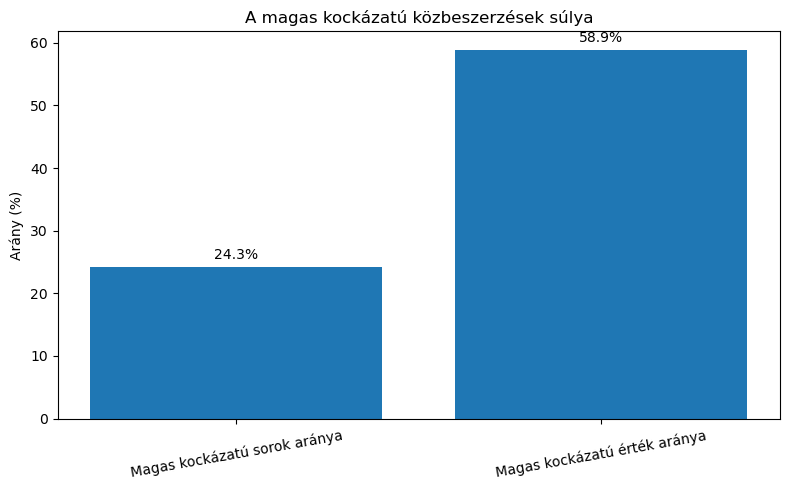

In [31]:
# magas kockázatú sorok és érték aránya

risk_row_pct = float(risk_summary.loc[risk_summary["mutató"] == "Magas kockázatú sorok aránya (%)", "érték"].iloc[0])
risk_value_pct = float(risk_summary.loc[risk_summary["mutató"] == "Magas kockázatú közbeszerzési érték aránya (%)", "érték"].iloc[0])

fig, ax = plt.subplots(figsize=(8, 5))

labels = ["Magas kockázatú sorok aránya", "Magas kockázatú érték aránya"]
values = [risk_row_pct, risk_value_pct]

ax.bar(labels, values)
ax.set_ylabel("Arány (%)")
ax.set_title("A magas kockázatú közbeszerzések súlya")
percent_label(ax, values)

plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

A magas kockázatú közbeszerzések a sorok kb. negyedét adják, de az érték közel 60%-át koncentrálják.

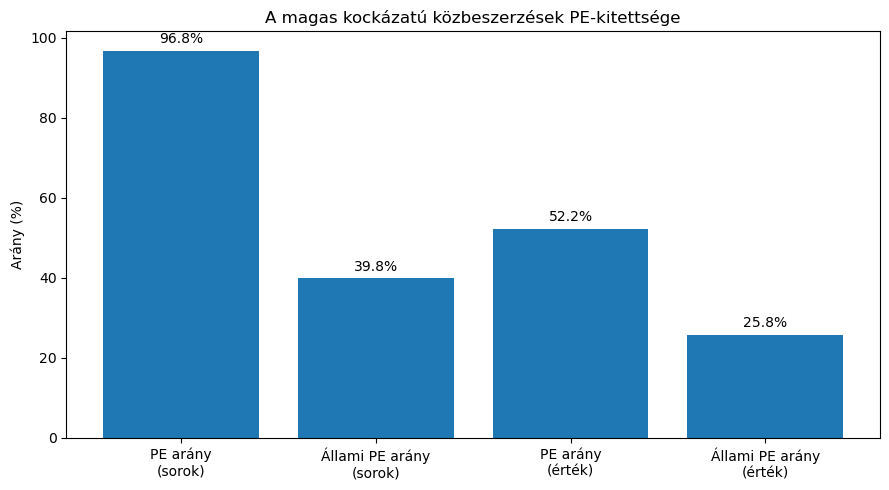

In [33]:
# magas kockázatúakon belül PE és állami PE arány

risky_pe_row_pct = float(risky_pe_summary.loc[
    risky_pe_summary["mutató"] == "PE-kapcsolatú arány a magas kockázatúakon belül (%)", "érték"
].iloc[0])

risky_state_pe_row_pct = float(risky_pe_summary.loc[
    risky_pe_summary["mutató"] == "Állami érintettségű PE-arány a magas kockázatúakon belül (%)", "érték"
].iloc[0])

risky_pe_value_pct = float(risky_pe_summary.loc[
    risky_pe_summary["mutató"] == "PE-kapcsolatú érték aránya a magas kockázatúakon belül (%)", "érték"
].iloc[0])

risky_state_pe_value_pct = float(risky_pe_summary.loc[
    risky_pe_summary["mutató"] == "Állami érintettségű PE-érték aránya a magas kockázatúakon belül (%)", "érték"
].iloc[0])

fig, ax = plt.subplots(figsize=(9, 5))

labels = [
    "PE arány\n(sorok)",
    "Állami PE arány\n(sorok)",
    "PE arány\n(érték)",
    "Állami PE arány\n(érték)"
]
values = [
    risky_pe_row_pct,
    risky_state_pe_row_pct,
    risky_pe_value_pct,
    risky_state_pe_value_pct
]

ax.bar(labels, values)
ax.set_ylabel("Arány (%)")
ax.set_title("A magas kockázatú közbeszerzések PE-kitettsége")
percent_label(ax, values)

plt.tight_layout()
plt.show()

A magas kockázatú tenderek döntő többsége PE-kapcsolatú, és értékben is több mint fele PE-kapcsolatú cégekhez kötődik.

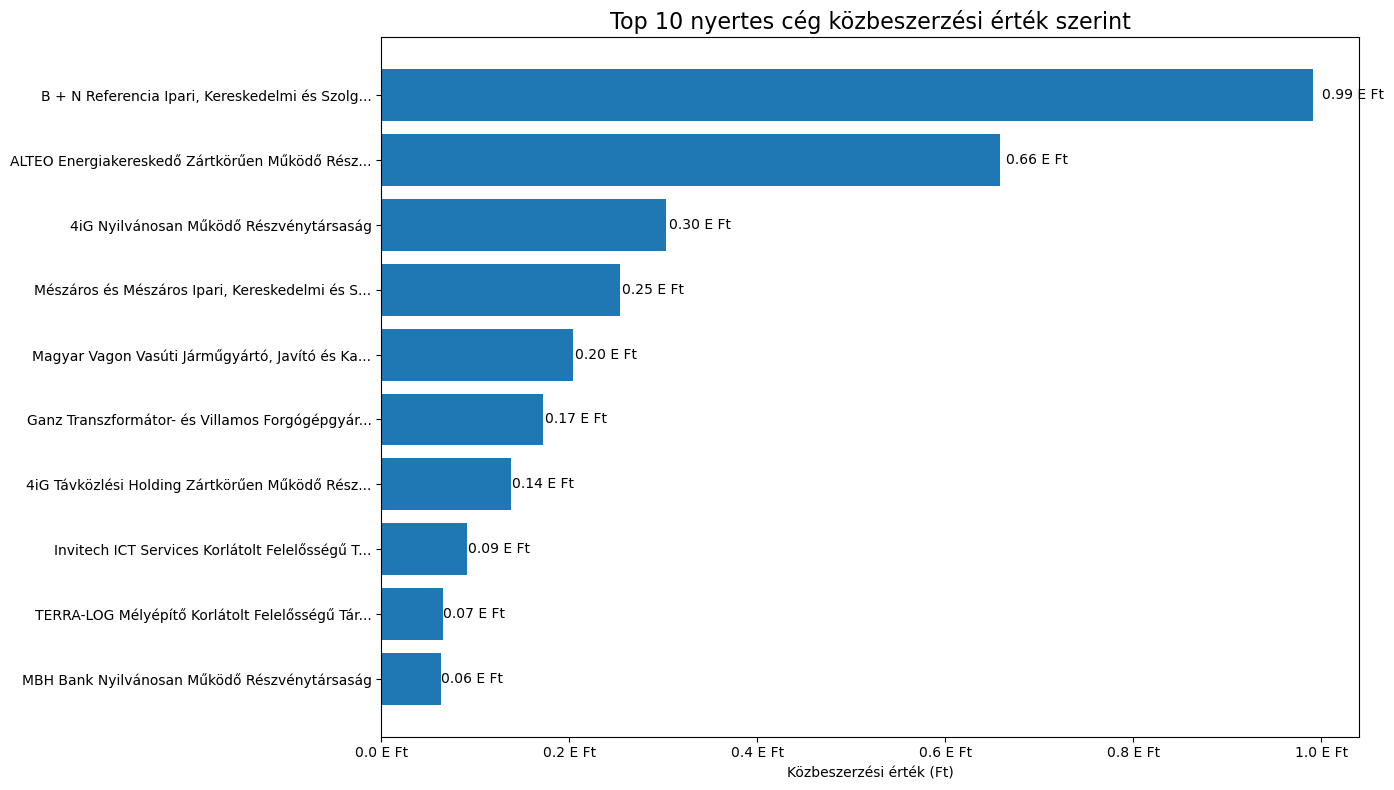

In [26]:
# Top 10 nyertes cég közbeszerzési érték szerint

def shorten_name(name, max_len=45):
    if len(name) > max_len:
        return name[:max_len] + "..."
    return name

top_companies = (
    analysis_df
    .groupby(["company_duns", "company_name_proc"], dropna=False)["proc_value_huf"]
    .sum()
    .reset_index()
    .sort_values("proc_value_huf", ascending=False)
    .head(10)
)

top_companies_plot = top_companies.sort_values("proc_value_huf")

labels = top_companies_plot["company_name_proc"].apply(shorten_name)
values = top_companies_plot["proc_value_huf"]

fig, ax = plt.subplots(figsize=(14, 8))

bars = ax.barh(labels, values)

ax.set_title("Top 10 nyertes cég közbeszerzési érték szerint", fontsize=16)
ax.set_xlabel("Közbeszerzési érték (Ft)")

ax.xaxis.set_major_formatter(FuncFormatter(trillions_formatter))

# érték kiírás a bar végére
for bar in bars:
    width = bar.get_width()
    ax.text(width * 1.01,
            bar.get_y() + bar.get_height()/2,
            f"{width/1e12:.2f} E Ft",
            va='center')

plt.tight_layout()
plt.show()

A nyertes értékek erősen néhány szereplőnél koncentrálódnak.

In [27]:
# Koncentrációs mutatók

company_value_summary = (
    analysis_df
    .groupby("company_duns", dropna=False)["proc_value_huf"]
    .sum()
    .sort_values(ascending=False)
)

total_company_value = company_value_summary.sum()
top5_share = company_value_summary.head(5).sum() / total_company_value * 100
top10_share = company_value_summary.head(10).sum() / total_company_value * 100
top20_share = company_value_summary.head(20).sum() / total_company_value * 100

concentration_summary = pd.DataFrame({
    "mutató": ["Top 5 részesedés (%)", "Top 10 részesedés (%)", "Top 20 részesedés (%)"],
    "érték": [round(top5_share, 2), round(top10_share, 2), round(top20_share, 2)]
})

display(concentration_summary)

,mutató,érték
0,Top 5 részesedés (%),71.53
1,Top 10 részesedés (%),87.28
2,Top 20 részesedés (%),96.28


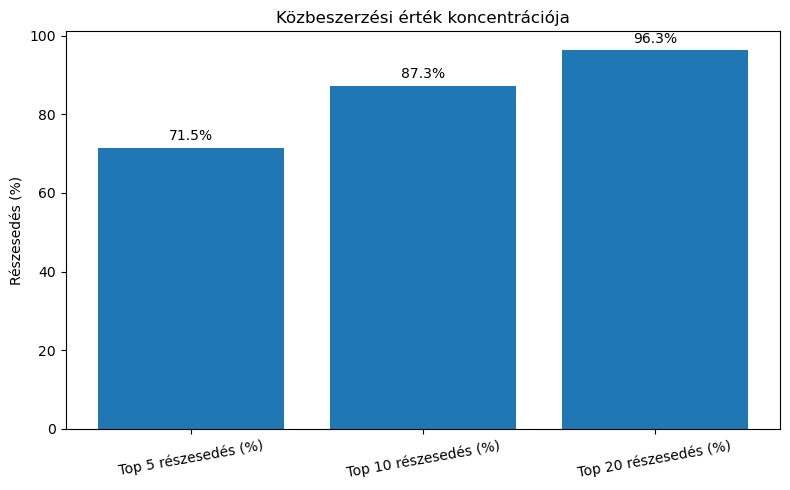

In [28]:
# koncentrációs oszlopdiagram

fig, ax = plt.subplots(figsize=(8, 5))

labels = concentration_summary["mutató"]
values = concentration_summary["érték"]

ax.bar(labels, values)
ax.set_ylabel("Részesedés (%)")
ax.set_title("Közbeszerzési érték koncentrációja")
percent_label(ax, values)

plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

A tenderérték jelentős része a legnagyobb szereplőkhöz koncentrálódik, ami szűk nyertesi kört jelez.

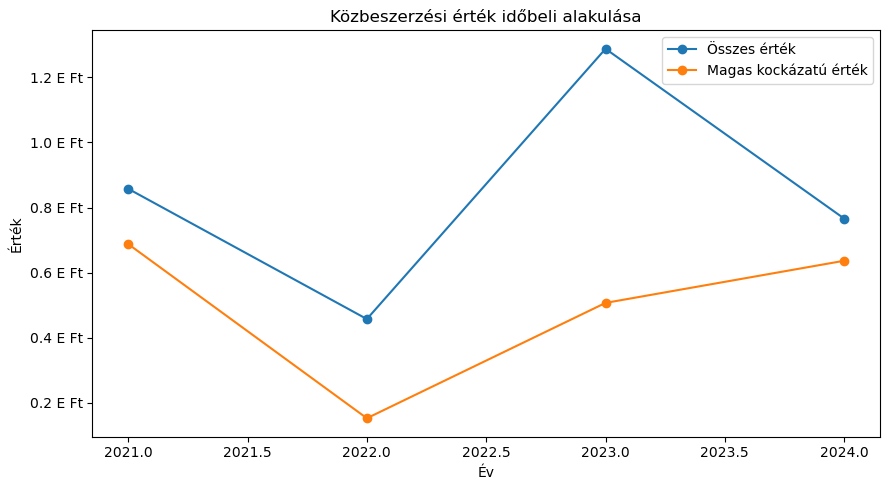

,year,total_value,risky_value
0,2021,857747890484.737549,687823480873.270996
1,2022,457257748915.449951,152421094703.072205
2,2023,1287942609705.547852,506989803876.666626
3,2024,766031560667.078247,636528971542.050049


In [ ]:
# Idővonal-magas kockázatú és összes érték évenként

analysis_df["year"] = analysis_df["notice_date"].dt.year

yearly_summary = (
    analysis_df
    .groupby("year", dropna=False)
    .agg(
        total_value=("proc_value_huf", "sum"),
        risky_value=("proc_value_huf", lambda x: x[analysis_df.loc[x.index, "risk_category"] == "magas"].sum())
    )
    .reset_index()
)

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(yearly_summary["year"], yearly_summary["total_value"], marker="o", label="Összes érték")
ax.plot(yearly_summary["year"], yearly_summary["risky_value"], marker="o", label="Magas kockázatú érték")

ax.set_title("Közbeszerzési érték időbeli alakulása")
ax.set_xlabel("Év")
ax.set_ylabel("Érték")
ax.yaxis.set_major_formatter(FuncFormatter(trillions_formatter))
ax.legend()

plt.tight_layout()
plt.show()

display(yearly_summary)

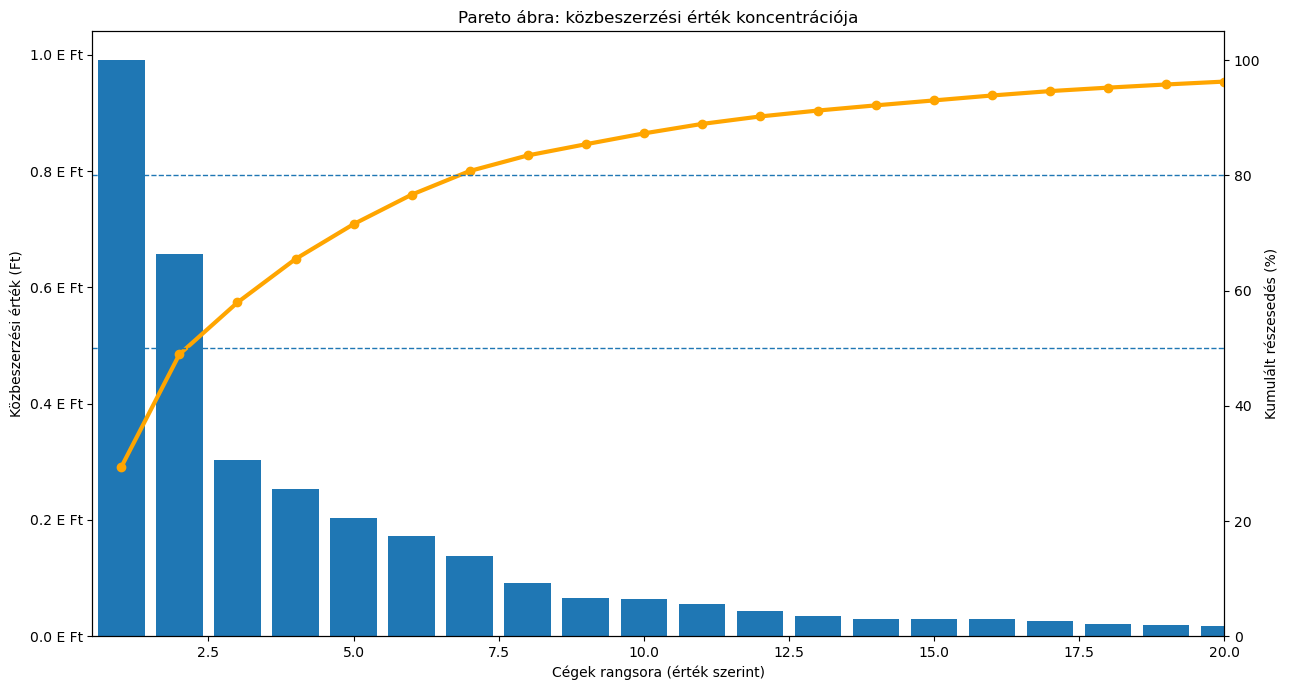

,rank,company_name_proc,proc_value_huf,share_pct,cum_share_pct
0,1,"B + N Referencia Ipari, Kereskedelmi és Szolgá...",990917332817.166626,29.412979,29.412979
1,2,ALTEO Energiakereskedő Zártkörűen Működő Részv...,658095184226.666626,19.53396,48.94694
2,3,4iG Nyilvánosan Működő Részvénytársaság,302885746408.447815,8.990429,57.937369
3,4,"Mészáros és Mészáros Ipari, Kereskedelmi és Sz...",254092109703.5,7.542108,65.479477
4,5,"Magyar Vagon Vasúti Járműgyártó, Javító és Kar...",203813999653.0,6.049725,71.529202
5,6,Ganz Transzformátor- és Villamos Forgógépgyárt...,172312363557.393311,5.114675,76.643877
6,7,4iG Távközlési Holding Zártkörűen Működő Részv...,138255992020.666656,4.103794,80.747671
7,8,Invitech ICT Services Korlátolt Felelősségű Tá...,91223399988.661606,2.707746,83.455416
8,9,TERRA-LOG Mélyépítő Korlátolt Felelősségű Társ...,65443388622.0,1.942528,85.397945
9,10,MBH Bank Nyilvánosan Működő Részvénytársaság,63286285994.0,1.8785,87.276445


In [35]:
#Pareto

pareto_df = (
    analysis_df
    .groupby(["company_duns", "company_name_proc"], dropna=False)["proc_value_huf"]
    .sum()
    .reset_index()
    .sort_values("proc_value_huf", ascending=False)
    .reset_index(drop=True)
)

pareto_df["rank"] = pareto_df.index + 1
pareto_df["share_pct"] = pareto_df["proc_value_huf"] / pareto_df["proc_value_huf"].sum() * 100
pareto_df["cum_share_pct"] = pareto_df["share_pct"].cumsum()

#top 20
pareto_plot = pareto_df.head(20)

fig, ax1 = plt.subplots(figsize=(13,7))

#oszlopok
ax1.bar(pareto_plot["rank"], pareto_plot["proc_value_huf"])

ax1.set_xlabel("Cégek rangsora (érték szerint)")
ax1.set_ylabel("Közbeszerzési érték (Ft)")
ax1.set_title("Pareto ábra: közbeszerzési érték koncentrációja")
ax1.set_xlim(0.5,20)
ax1.yaxis.set_major_formatter(FuncFormatter(trillions_formatter))

#kumulált vonal
ax2 = ax1.twinx()

ax2.plot(
    pareto_plot["rank"],
    pareto_plot["cum_share_pct"],
    color="orange",
    marker="o",
    linewidth=3
)

ax2.set_ylabel("Kumulált részesedés (%)")
ax2.set_ylim(0,105)

ax2.axhline(50, linestyle="--", linewidth=1)
ax2.axhline(80, linestyle="--", linewidth=1)

plt.tight_layout()
plt.show()

display(pareto_plot[[
    "rank", "company_name_proc", "proc_value_huf", "share_pct", "cum_share_pct"
]])